# CellBridge on NuCLS

Prepare H&E images → extract cell embeddings → fit a classifier → inspect COF prediction sets.

We use the **released CellBridge encoder** and NuCLS's existing cell annotations and splits.
No encoder training, TERRA embeddings, or new cell segmentation is needed.
NuCLS labels are used to fit and evaluate a linear classifier and calibrate COF.

## 1. Setup

Follow the [installation guide](../REPRODUCIBILITY.md#installation-options) in a **Python 3.11**
environment, including the model dependencies and `requirements/encoders.txt`.
A GPU is recommended for image encoding.
From the repository root:

```bash
python -m pip install '.[analysis]'
python -m ipykernel install --user --name cellbridge --display-name "CellBridge (Python 3.11)"
python -m jupyterlab notebooks/TUTORIAL.ipynb
```

Choose the **CellBridge (Python 3.11)** kernel and run the cells in order.
The dataset archive is about **0.8 GB** and extracted data, model weights, and embeddings need additional disk space.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from PIL import Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "configs/inference/nucls.yaml").is_file())
WORK = ROOT / "outputs" / "tutorial"
DATA = WORK / "data" / "eval" / "nucls"
RUN = WORK / "results" / "nucls"
CONFIG = ROOT / "configs/inference/nucls.yaml"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

os.environ.update({
    "CELLBRIDGE_ROOT": str(ROOT),
    "CELLBRIDGE_DATA_ROOT": str(WORK / "data"),
    "CELLBRIDGE_OUTPUTS_ROOT": str(WORK / "results"),
})
print(f"Device: {DEVICE} | Tutorial files: {WORK}")

Device: cuda | Tutorial files: /lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/outputs/tutorial


Request access to [UNI2-h](https://huggingface.co/MahmoodLab/UNI2-h) and authenticate below.

In [2]:
from huggingface_hub import get_token, notebook_login

if get_token() is None:
    notebook_login()

## 2. Prepare NuCLS

This command downloads the images and annotations and prepares the fixed train/validation/test split.
It reuses the downloaded archive on subsequent runs.
To use an existing archive, append `"--archive", "/path/to/NuCLS_dataset.zip"` to the argument list.

,annotated_cells
split,
test,7150
train,33972
val,18363


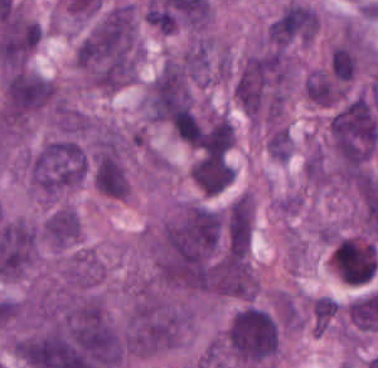

In [3]:
subprocess.run(
    [sys.executable, "-m", "cellbridge.inference.prepare.nucls", str(DATA)],
    check=True,
)
metadata = pd.read_csv(DATA / "nucls_info.csv", dtype={"row_id": str})
display(metadata.groupby("split").size().rename("annotated_cells").to_frame())
with Image.open(DATA / "raw/rgb" / metadata.iloc[0]["image_name"]) as image:
    display(image.copy())

## 3. Check inputs and extract embeddings

We select only CellBridge features and the linear probe.
`check` validates the inputs and downloads the adapter if needed.
`extract` loads UNI2-h, applies the adapter, and saves one embedding per included cell.
No classifier is fitted yet.

In [4]:
def infer(stage):
    subprocess.run([
        sys.executable, "-m", "cellbridge.inference.run", stage,
        "--config", str(CONFIG), "--method", "cellbridge",
        "--arm", "lora_adapted", "--probe", "linear",
        "--output-dir", str(RUN), "--device", DEVICE,
    ], check=True)

infer("check")

Conformal: alpha=0.1, 51,345/51,970 mapped cells
Bootstrap: 22 independent test groups
nucls: 51,970 cells, 1741 labeled samples
Methods: cellbridge
Tasks: all
Probes: linear
Output: /lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/outputs/tutorial/results/nucls


This step may take around 15 minutes!

In [5]:
infer("extract")

[cellbridge] TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_left-11371_top-54469_bottom-54761_right-11671: 32 cells
[cellbridge] TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_left-11391_top-53955_bottom-54237_right-11688: 42 cells
[cellbridge] TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_left-11653_top-54468_bottom-54777_right-11941: 25 cells
[cellbridge] TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_left-11841_top-57182_bottom-57525_right-12205: 36 cells
[cellbridge] TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_left-11868_top-53956_bottom-54243_right-12182: 30 cells
[cellbridge] TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_left-11897_top-54213_bottom-54513_right-12210: 23 cells
[cellbridge] TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_left-11917_top-54733_bottom-54999_right-12199: 13 cells
[cellbridge] TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_left-7053_top-53967_bottom-54231_right-7311: 12 cells
[cellbridge] TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_left-7807_top-53960_bottom-54248

In [6]:
manifest = pd.read_csv(RUN / "embeddings/lora_adapted/manifest.csv")
print(f"Saved {manifest.n_cells.sum():,} cell embeddings across {len(manifest)} images.")
display(manifest[["sample_id", "n_cells", "n_features"]].head())

Saved 51,970 cell embeddings across 1741 images.


,sample_id,n_cells,n_features
0,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...,32,1536
1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...,42,1536
2,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...,25,1536
3,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...,36,1536
4,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...,30,1536


## 4. Evaluate the classifier

`evaluate` fits a linear classifier using the saved embeddings and reports held-out test performance.

In [7]:
infer("evaluate")
EVAL = RUN / "evaluation/lora_adapted/all/linear"
metrics = pd.read_csv(EVAL / "metrics.csv")
display(metrics[["macro_f1", "balanced_accuracy", "macro_auroc"]].round(3))

[cellbridge/lora_adapted/all/linear] macro_f1=0.4121, bootstrap_se=0.0278


,macro_f1,balanced_accuracy,macro_auroc
0,0.412,0.408,0.92


## 5. Calibrate and evaluate COF

`conformal` fits a separate classifier on training cells and uses validation cells for calibration.
It evaluates prediction sets on test cells at a target coverage of **90%**.
Ontology mapping and minimum class support can exclude cells from this stage.
CellBridge's **Cell-Ontology-Fallback (COF)** method corresponds to `branch_graph`.

In [8]:
infer("conformal")
COF = EVAL / "conformal_prediction"
cof_metrics = pd.read_csv(COF / "metrics.csv")
display(cof_metrics.loc[cof_metrics.conformal_method == "branch_graph", [
    "marginal_coverage", "mean_prediction_set_size", "singleton_rate",
]].round(3))

Excluded classes with fewer than 20 cells per split: duct epithelial cell, endothelial cell, eosinophil, myoepithelial cell, neutrophil
[cellbridge/lora_adapted/all/linear/conformal_prediction] coverage=0.9218, size=1.97


,marginal_coverage,mean_prediction_set_size,singleton_rate
2,0.953,2.724,0.395


## 6. Inspect individual predictions

A singleton set gives one cell label. Larger sets retain several plausible labels.

In [9]:
with np.load(COF / "predictions.npz", allow_pickle=False) as saved:
    classes = saved["classes"].astype(str)
    sets = saved["branch_graph_sets"]
    predictions = pd.DataFrame({
        "row_id": saved["ids"].astype(str),
        "true_label": saved["y_true"].astype(str),
        "prediction_set": [", ".join(classes[mask]) for mask in sets],
        "set_size": sets.sum(axis=1),
    })

# Join by saved cell identity, not by CSV row order.
predictions = predictions.merge(
    metadata[["row_id", "image_name"]], on="row_id", validate="one_to_one",
)
display(predictions.head(10))
print(f"All results are saved under {RUN}")

,row_id,true_label,prediction_set,set_size,image_name
0,0,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
1,1,tumor cell,"fibroblast, lymphocyte, macrophage, plasma cel...",5,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
2,2,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
3,3,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
4,4,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
5,5,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
6,6,tumor cell,"fibroblast, lymphocyte, macrophage, plasma cel...",5,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
7,7,tumor cell,"fibroblast, lymphocyte, macrophage, plasma cel...",5,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
8,8,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...
9,9,tumor cell,tumor cell,1,TCGA-A1-A0SP-DX1_id-5ea4095addda5f8398977ebc_l...


All results are saved under /lustre/scratch126/cellgen/lotfollahi/so25/projects/cellbridge/outputs/tutorial/results/nucls


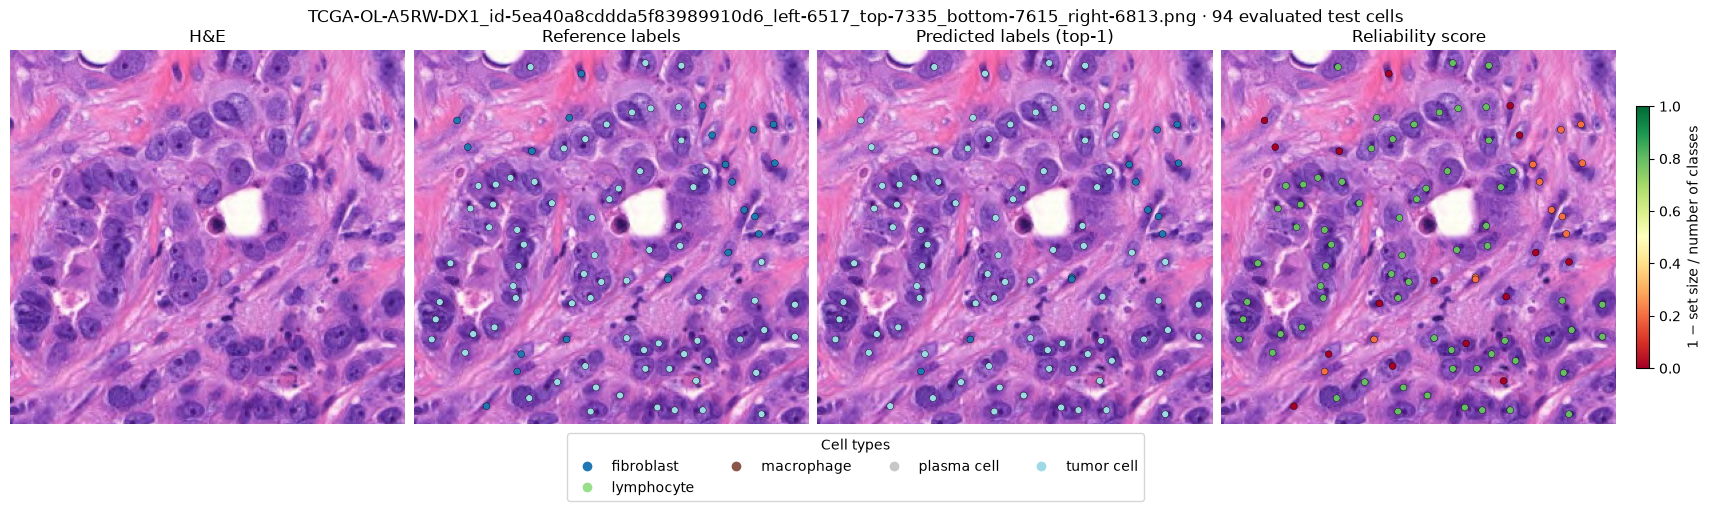

In [10]:
# Qualitative inspection: paper Eq. 10, R = 1 - |C| / |Y|.
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

with np.load(COF / "predictions.npz", allow_pickle=False) as saved:
    top1 = pd.DataFrame({
        "row_id": saved["ids"].astype(str),
        "predicted_label": classes[saved["probabilities"].argmax(axis=1)],
    })
view = predictions.merge(top1, on="row_id", validate="one_to_one").merge(
    metadata[["row_id", "x", "y"]], on="row_id", validate="one_to_one",
)
view["reliability"] = 1 - view["set_size"] / len(classes)
image_name = view["image_name"].value_counts().index[0]  # Change to inspect another image.
cells = view.loc[view["image_name"] == image_name]
with Image.open(DATA / "raw/rgb" / image_name) as image:
    tissue = np.asarray(image.convert("RGB"))

fig, axes = plt.subplots(1, 4, figsize=(17, 5), layout="constrained")
for ax, title in zip(axes, ["H&E", "Reference labels", "Predicted labels (top-1)", "Reliability score"]):
    ax.imshow(tissue)
    ax.set_title(title)
    ax.axis("off")
colours = plt.get_cmap("tab20", len(classes))
for ax, column in zip(axes[1:3], ["true_label", "predicted_label"]):
    codes = pd.Categorical(cells[column], categories=classes).codes
    ax.scatter(cells.x, cells.y, c=codes, cmap=colours, vmin=-0.5,
               vmax=len(classes) - 0.5, s=24, edgecolors="black", linewidths=0.3)
nonempty = cells["set_size"] > 0
points = axes[3].scatter(cells.loc[nonempty, "x"], cells.loc[nonempty, "y"],
                         c=cells.loc[nonempty, "reliability"], cmap="RdYlGn",
                         vmin=0, vmax=1, s=24, edgecolors="black", linewidths=0.3)
if (~nonempty).any():
    axes[3].scatter(cells.loc[~nonempty, "x"], cells.loc[~nonempty, "y"],
                    c="gray", marker="x", s=30, label="Empty set")
    axes[3].legend(loc="lower right")
fig.colorbar(points, ax=axes[3], label="1 − set size / number of classes", shrink=0.7)
handles = [Line2D([], [], marker="o", linestyle="", color=colours(i), label=label)
           for i, label in enumerate(classes)]
fig.legend(handles=handles, loc="outside lower center", ncol=4, title="Cell types")
fig.suptitle(f"{image_name} · {len(cells)} evaluated test cells")
plt.show()

The main files are:

- `embeddings/lora_adapted/manifest.csv`: saved image embeddings.
- `evaluation/lora_adapted/all/linear/metrics.csv`: classification metrics.
- `evaluation/lora_adapted/all/linear/conformal_prediction/predictions.npz`: COF sets and labels.

For the complete paper experiments, follow the [reproducibility guide](../REPRODUCIBILITY.md#experimental-results).